# Synthetic Tests of Independence of Irrelevant Alternatives

## Objective

Study how often two likelihood-ratio tests reject the MNL model
when observations are generated by:

1. An MNL model, where IIA holds.
2. A full CDM, which can represent context-dependent choices.
3. A general choice system with separately specified probabilities
   for each choice set.

We compare MNL against two alternatives: full CDM and the
universal choice model.

The experiment reports rejection proportions across repeated
datasets as the number of observations increases.

In [1]:
# Import dependencies and locate the project and reusable model modules.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from IPython.display import display

import cdm_paper_reproduction.estimation as paper_estimation
import cdm_paper_reproduction.synthetic as paper_synthetic
import context_dependent_model as cdm

current_directory = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        directory
        for directory in (
            current_directory,
            *current_directory.parents,
        )
        if (directory / "pyproject.toml").is_file()
        and (directory / "src").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root containing pyproject.toml and src."
    )

print("Project root:", PROJECT_ROOT)
print("Synthetic module:", paper_synthetic.__file__)
print("Estimation module:", paper_estimation.__file__)

Project root: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-
Synthetic module: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/src/cdm_paper_reproduction/synthetic.py
Estimation module: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/src/cdm_paper_reproduction/estimation.py


In [2]:
# Configure the synthetic IIA pilot and create its output directories.

SEED = 20260831
NUMBER_OF_ITEMS = 6
SIGNIFICANCE_LEVEL = 0.05
PILOT_NUMBER_OF_RUNS = 10

OBSERVATION_COUNTS = (
    100,
    200,
    400,
    600,
    800,
    1_000,
    1_500,
    2_000,
)

DEVICE = torch.device("cpu")
DTYPE = torch.float64

GENERATING_MODELS = (
    "MNL",
    "CDM",
    "General choice",
)

EXPERIMENT_NAME = "02_synthetic_iia_tests"
experiment_path = (
    Path("cdm_paper_reproduction") / EXPERIMENT_NAME
)

FIGURE_DIRECTORY = (
    PROJECT_ROOT
    / "docs"
    / "thesis"
    / "images"
    / "experiments"
    / experiment_path
)

TABLE_DIRECTORY = (
    PROJECT_ROOT
    / "docs"
    / "thesis"
    / "tables"
    / "experiments"
    / experiment_path
)

RESULT_DIRECTORY = (
    PROJECT_ROOT
    / "results"
    / "experiments"
    / experiment_path
)

for directory in (
    FIGURE_DIRECTORY,
    TABLE_DIRECTORY,
    RESULT_DIRECTORY,
):
    directory.mkdir(parents=True, exist_ok=True)

iia_settings = pd.DataFrame({
    "Setting": [
        "Random seed",
        "Number of items",
        "Significance level",
        "Pilot repetitions",
        "Observation counts",
        "Generating models",
        "Device",
        "Dtype",
    ],
    "Value": [
        SEED,
        NUMBER_OF_ITEMS,
        SIGNIFICANCE_LEVEL,
        PILOT_NUMBER_OF_RUNS,
        str(OBSERVATION_COUNTS),
        ", ".join(GENERATING_MODELS),
        str(DEVICE),
        str(DTYPE),
    ],
})

display(iia_settings)

iia_settings.to_csv(
    RESULT_DIRECTORY / "pilot_settings.csv",
    index=False,
)

,Setting,Value
0,Random seed,20260831
1,Number of items,6
2,Significance level,0.05
3,Pilot repetitions,10
4,Observation counts,"(100, 200, 400, 600, 800, 1000, 1500, 2000)"
5,Generating models,"MNL, CDM, General choice"
6,Device,cpu
7,Dtype,torch.float64


In [3]:
# Enumerate all valid choice sets for the six-item experiment.

from cdm_paper_reproduction.iia_simulation import (
    enumerate_choice_sets,
    generate_general_choice_probabilities,
    sample_choices_from_probability_table,
)

catalogue_choice_sets, catalogue_choice_mask = enumerate_choice_sets(
    number_of_items=NUMBER_OF_ITEMS,
    device=DEVICE,
)

catalogue_sizes = catalogue_choice_mask.sum(dim=1)

catalogue_summary = (
    pd.Series(
        catalogue_sizes.cpu().numpy(),
        name="Choice-set size",
    )
    .value_counts()
    .sort_index()
    .rename("Number of possible menus")
    .reset_index()
)

assert len(catalogue_choice_sets) == (
    2**NUMBER_OF_ITEMS - NUMBER_OF_ITEMS - 1
)

display(catalogue_summary)

print("Catalogue shape:", tuple(catalogue_choice_sets.shape))
print("Total possible menus:", len(catalogue_choice_sets))
print("\nFirst five padded menus:")
print(catalogue_choice_sets[:5])

,Choice-set size,Number of possible menus
0,2,15
1,3,20
2,4,15
3,5,6
4,6,1


Catalogue shape: (57, 6)
Total possible menus: 57

First five padded menus:
tensor([[ 0,  1, -1, -1, -1, -1],
        [ 0,  2, -1, -1, -1, -1],
        [ 0,  3, -1, -1, -1, -1],
        [ 0,  4, -1, -1, -1, -1],
        [ 0,  5, -1, -1, -1, -1]])


In [4]:
# Construct fixed probability tables for the three generating models.

MNL_PARAMETER_CONVENTION = "positive_luce_weights"
CDM_PARAMETER_SEED = SEED + 100
GENERAL_PARAMETER_SEED = SEED + 101

true_mnl_weights = torch.arange(
    1,
    NUMBER_OF_ITEMS + 1,
    device=DEVICE,
    dtype=DTYPE,
)
true_mnl_weights = true_mnl_weights / true_mnl_weights.sum()

true_mnl_log_utilities = true_mnl_weights.log()
true_mnl_log_utilities -= true_mnl_log_utilities.mean()

safe_catalogue_items = catalogue_choice_sets.clamp_min(0)

mnl_menu_weights = true_mnl_weights[safe_catalogue_items]
mnl_menu_weights = mnl_menu_weights.masked_fill(
    ~catalogue_choice_mask,
    0.0,
)

mnl_probability_table = (
    mnl_menu_weights
    / mnl_menu_weights.sum(dim=1, keepdim=True)
)

(
    iia_true_target_vectors,
    iia_true_context_vectors,
    iia_true_interactions,
) = paper_synthetic.generate_paper_cdm_parameters(
    number_of_items=NUMBER_OF_ITEMS,
    random_seed=CDM_PARAMETER_SEED,
    device=DEVICE,
    dtype=DTYPE,
)

with torch.no_grad():
    cdm_probability_table = cdm.cdm_choice_probabilities(
        interaction_matrix=iia_true_interactions,
        choice_sets=catalogue_choice_sets,
        choice_mask=catalogue_choice_mask,
    )

general_probability_table = generate_general_choice_probabilities(
    choice_mask=catalogue_choice_mask,
    random_seed=GENERAL_PARAMETER_SEED,
    dtype=DTYPE,
)

true_probability_tables = {
    "MNL": mnl_probability_table,
    "CDM": cdm_probability_table,
    "General choice": general_probability_table,
}

display(
    pd.DataFrame({
        "Item": range(NUMBER_OF_ITEMS),
        "True Luce weight": true_mnl_weights.cpu().numpy(),
        "Centred log-utility": (
            true_mnl_log_utilities.cpu().numpy()
        ),
    }).style.format({
        "True Luce weight": "{:.4f}",
        "Centred log-utility": "{:.4f}",
    })
)

,Item,True Luce weight,Centred log-utility
0,0,0.0476,-1.0965
1,1,0.0952,-0.4034
2,2,0.1429,0.0021
3,3,0.1905,0.2898
4,4,0.2381,0.5129
5,5,0.2857,0.6952


In [5]:
# Validate the probability tables and compare the same three-item menu.

probability_check_rows = []

for model_name, probabilities in true_probability_tables.items():
    assert torch.isfinite(probabilities).all().item()
    assert (probabilities >= 0).all().item()
    assert (probabilities[~catalogue_choice_mask] == 0).all().item()

    row_sum_error = (
        probabilities.sum(dim=1) - 1.0
    ).abs().max().item()

    assert row_sum_error < 1e-10

    probability_check_rows.append({
        "Generating model": model_name,
        "Menus": len(probabilities),
        "Maximum probability-sum error": row_sum_error,
        "Minimum valid probability": (
            probabilities[catalogue_choice_mask].min().item()
        ),
    })

display(pd.DataFrame(probability_check_rows))

example_menu = (0, 1, 2)

example_menu_index = next(
    row
    for row in range(len(catalogue_choice_sets))
    if tuple(
        catalogue_choice_sets[row][
            catalogue_choice_mask[row]
        ].cpu().tolist()
    ) == example_menu
)

example_probability_table = pd.DataFrame({
    "Item": example_menu,
    **{
        model_name: probabilities[
            example_menu_index,
            catalogue_choice_mask[example_menu_index],
        ].cpu().numpy()
        for model_name, probabilities
        in true_probability_tables.items()
    },
})

display(
    example_probability_table.style.format({
        model_name: "{:.4f}"
        for model_name in GENERATING_MODELS
    })
)

,Generating model,Menus,Maximum probability-sum error,Minimum valid probability
0,MNL,57,2.220446e-16,0.047619
1,CDM,57,2.220446e-16,0.000017
2,General choice,57,2.220446e-16,0.001654


,Item,MNL,CDM,General choice
0,0,0.1667,0.0024,0.5976
1,1,0.3333,0.9974,0.2397
2,2,0.5000,0.0002,0.1627


In [6]:
# Generate and save three demonstration datasets on the same sampled menus.

import json

DEMO_NUMBER_OF_OBSERVATIONS = max(OBSERVATION_COUNTS)
DEMO_MENU_SEED = SEED + 200

demo_outcome_seeds = {
    "MNL": SEED + 301,
    "CDM": SEED + 302,
    "General choice": SEED + 303,
}

menu_generator = torch.Generator(device="cpu")
menu_generator.manual_seed(DEMO_MENU_SEED)

demo_menu_indices = torch.randint(
    low=0,
    high=len(catalogue_choice_sets),
    size=(DEMO_NUMBER_OF_OBSERVATIONS,),
    generator=menu_generator,
).to(DEVICE)

demo_datasets = {}

for model_name, probabilities in true_probability_tables.items():
    demo_datasets[model_name] = (
        sample_choices_from_probability_table(
            catalogue_choice_sets=catalogue_choice_sets,
            catalogue_choice_mask=catalogue_choice_mask,
            probability_table=probabilities,
            menu_indices=demo_menu_indices,
            random_seed=demo_outcome_seeds[model_name],
        )
    )

demo_preview = pd.DataFrame({
    "Choice set": [
        tuple(
            catalogue_choice_sets[index][
                catalogue_choice_mask[index]
            ].cpu().tolist()
        )
        for index in demo_menu_indices[:10].cpu().tolist()
    ],
    **{
        f"{model_name} choice": data.chosen_items[:10].cpu().numpy()
        for model_name, data in demo_datasets.items()
    },
})

display(demo_preview)

for model_name, data in demo_datasets.items():
    chosen_is_available = (
        data.choice_sets.eq(data.chosen_items.unsqueeze(1))
        & data.choice_mask
    ).any(dim=1)

    assert chosen_is_available.all().item()

    model_filename = model_name.lower().replace(" ", "_")

    np.savez_compressed(
        RESULT_DIRECTORY / f"demo_{model_filename}.npz",
        choice_sets=data.choice_sets.cpu().numpy(),
        choice_mask=data.choice_mask.cpu().numpy(),
        chosen_positions=data.chosen_positions.cpu().numpy(),
        probability_table=(
            true_probability_tables[model_name].cpu().numpy()
        ),
    )

np.savez_compressed(
    RESULT_DIRECTORY / "demo_generating_parameters.npz",
    catalogue_choice_sets=catalogue_choice_sets.cpu().numpy(),
    catalogue_choice_mask=catalogue_choice_mask.cpu().numpy(),
    menu_indices=demo_menu_indices.cpu().numpy(),
    mnl_weights=true_mnl_weights.cpu().numpy(),
    mnl_log_utilities=true_mnl_log_utilities.cpu().numpy(),
    cdm_interactions=iia_true_interactions.cpu().numpy(),
)

demo_settings = {
    "number_of_items": NUMBER_OF_ITEMS,
    "number_of_observations": DEMO_NUMBER_OF_OBSERVATIONS,
    "mnl_parameter_convention": MNL_PARAMETER_CONVENTION,
    "cdm_parameter_seed": CDM_PARAMETER_SEED,
    "general_parameter_seed": GENERAL_PARAMETER_SEED,
    "menu_seed": DEMO_MENU_SEED,
    "outcome_seeds": demo_outcome_seeds,
    "menu_sampling": "uniform over all subsets of size at least two",
}

(RESULT_DIRECTORY / "demo_settings.json").write_text(
    json.dumps(demo_settings, indent=2),
    encoding="utf-8",
)

print(
    f"Generated {DEMO_NUMBER_OF_OBSERVATIONS:,} observations "
    "for each of the three models."
)
print("Every chosen item belongs to its observed menu.")
print("Saved datasets and generating settings:", RESULT_DIRECTORY)

,Choice set,MNL choice,CDM choice,General choice choice
0,"(0, 2, 3)",2,0,2
1,"(0, 2, 3, 4)",4,0,2
2,"(1, 3, 4, 5)",3,4,5
3,"(0, 4, 5)",5,5,5
4,"(2, 3, 5)",5,5,3
5,"(2, 4, 5)",5,2,4
6,"(1, 4, 5)",4,4,5
7,"(2, 3, 4, 5)",4,4,4
8,"(1, 4, 5)",4,4,4
9,"(0, 2, 4, 5)",5,5,4


Generated 2,000 observations for each of the three models.
Every chosen item belongs to its observed menu.
Saved datasets and generating settings: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/experiments/cdm_paper_reproduction/02_synthetic_iia_tests


## Fit MNL and Full CDM to Each Generated Dataset

For each generating model, fit MNL and full CDM to the same observed
choices. Initialize the full CDM using the fitted MNL probabilities.

Compare maximized training likelihoods and inspect optimization diagnostics.
These fits will subsequently be used for likelihood-ratio tests of IIA.

All observations are used for fitting here because the likelihood-ratio
comparison evaluates both models on the same sample.

In [7]:
# Fit an unregularized MNL model to each generated dataset.

from bradley_terry.choix_estimation import (
    estimate_top1_parameters_with_choix,
)

mnl_fits = {}

for generating_model, data in demo_datasets.items():
    observations = [
        (
            int(chosen_item),
            tuple(int(item) for item in choice_set[mask].tolist()),
        )
        for chosen_item, choice_set, mask in zip(
            data.chosen_items,
            data.choice_sets,
            data.choice_mask,
        )
    ]

    estimated_parameters = estimate_top1_parameters_with_choix(
        number_of_items=NUMBER_OF_ITEMS,
        observations=observations,
        alpha=0.0,
        maximum_iterations=10_000,
        tolerance=1e-10,
    )

    parameters = torch.as_tensor(
        estimated_parameters,
        dtype=DTYPE,
        device=data.choice_sets.device,
    )

    with torch.no_grad():
        utilities = parameters[
            data.choice_sets.clamp_min(0)
        ].masked_fill(~data.choice_mask, -torch.inf)

        chosen_utilities = utilities.gather(
            dim=1,
            index=data.chosen_positions.unsqueeze(1),
        ).squeeze(1)

        mean_nll = (
            torch.logsumexp(utilities, dim=1)
            - chosen_utilities
        ).mean().item()

    mnl_fits[generating_model] = {
        "parameters": parameters,
        "mean_nll": mean_nll,
        "number_of_observations": len(observations),
    }

    print(
        f"{generating_model} data | "
        f"MNL mean NLL = {mean_nll:.6f}"
    )

MNL data | MNL mean NLL = 1.035241
CDM data | MNL mean NLL = 0.861369
General choice data | MNL mean NLL = 1.116058


In [8]:
# Construct CDM initializations that reproduce the fitted MNL probabilities.

initial_cdm_interactions = {}
initialization_check_rows = []

for generating_model, data in demo_datasets.items():
    parameters = mnl_fits[generating_model]["parameters"]

    initial_interactions = (
        -parameters.unsqueeze(0)
        .expand(NUMBER_OF_ITEMS, -1)
        .clone()
    )

    initial_interactions = cdm.center_cdm_parameters(
        initial_interactions
    )

    with torch.no_grad():
        mnl_utilities = parameters[
            data.choice_sets.clamp_min(0)
        ].masked_fill(~data.choice_mask, -torch.inf)

        mnl_probabilities = torch.softmax(
            mnl_utilities,
            dim=1,
        )

        initial_cdm_probabilities = cdm.cdm_choice_probabilities(
            interaction_matrix=initial_interactions,
            choice_sets=data.choice_sets,
            choice_mask=data.choice_mask,
        )

        maximum_probability_difference = (
            mnl_probabilities - initial_cdm_probabilities
        ).abs().max().item()

    assert maximum_probability_difference < 1e-10, (
        f"MNL initialization mismatch for {generating_model}."
    )

    initial_cdm_interactions[generating_model] = (
        initial_interactions
    )

    initialization_check_rows.append({
        "Generating model": generating_model,
        "Maximum probability difference": (
            maximum_probability_difference
        ),
    })

initialization_check = pd.DataFrame(
    initialization_check_rows
)

display(
    initialization_check.style.format({
        "Maximum probability difference": "{:.2e}",
    })
)

,Generating model,Maximum probability difference
0,MNL,5.55e-17
1,CDM,1.11e-16
2,General choice,5.55e-17


In [9]:
# Fit the full CDM from the equivalent MNL initialization.

cdm_fits = {}
cdm_fit_rows = []

for generating_model, data in demo_datasets.items():
    print(f"Fitting full CDM to {generating_model} data...")

    result = paper_estimation.optimize_full_cdm_with_adam(
        number_of_items=NUMBER_OF_ITEMS,
        training_data=data,
        initial_interactions=(
            initial_cdm_interactions[generating_model]
        ),
        learning_rate=0.05,
        gradient_tolerance=1e-5,
        nll_tolerance=1e-9,
        patience=50,
        maximum_epochs=5_000,
        dtype=DTYPE,
    )

    with torch.no_grad():
        fitted_nll = cdm.average_cdm_negative_log_likelihood(
            interaction_matrix=result.interaction_matrix,
            choice_sets=data.choice_sets,
            chosen_positions=data.chosen_positions,
            choice_mask=data.choice_mask,
        ).item()

    cdm_fits[generating_model] = result

    cdm_fit_rows.append({
        "Generating model": generating_model,
        "CDM mean NLL": fitted_nll,
        "CDM epochs": result.epochs_completed,
        "CDM runtime (seconds)": result.runtime_seconds,
        "CDM converged": result.converged,
        "CDM stopping reason": result.stopping_reason,
    })

    print(
        f"  NLL = {fitted_nll:.6f} | "
        f"epochs = {result.epochs_completed} | "
        f"converged = {result.converged}"
    )

Fitting full CDM to MNL data...
  NLL = 1.028059 | epochs = 143 | converged = True
Fitting full CDM to CDM data...
  NLL = 0.364798 | epochs = 1254 | converged = True
Fitting full CDM to General choice data...
  NLL = 1.083702 | epochs = 153 | converged = True


In [10]:
# Compare fitted likelihoods and save the demo fitting results.

demo_fit_summary = pd.DataFrame(cdm_fit_rows)

demo_fit_summary["Observations"] = (
    demo_fit_summary["Generating model"].map({
        name: fit["number_of_observations"]
        for name, fit in mnl_fits.items()
    })
)

demo_fit_summary["MNL mean NLL"] = (
    demo_fit_summary["Generating model"].map({
        name: fit["mean_nll"]
        for name, fit in mnl_fits.items()
    })
)

demo_fit_summary["NLL improvement over MNL"] = (
    demo_fit_summary["MNL mean NLL"]
    - demo_fit_summary["CDM mean NLL"]
)

demo_fit_summary["CDM no worse than MNL"] = (
    demo_fit_summary["NLL improvement over MNL"] >= -1e-8
)

demo_fit_summary = demo_fit_summary[
    [
        "Generating model",
        "Observations",
        "MNL mean NLL",
        "CDM mean NLL",
        "NLL improvement over MNL",
        "CDM no worse than MNL",
        "CDM converged",
        "CDM epochs",
        "CDM runtime (seconds)",
        "CDM stopping reason",
    ]
]

RESULT_DIRECTORY.mkdir(parents=True, exist_ok=True)

demo_fit_summary.to_csv(
    RESULT_DIRECTORY / "demo_fit_summary.csv",
    index=False,
)

for generating_model, result in cdm_fits.items():
    model_slug = generating_model.lower().replace(" ", "_")

    np.savez_compressed(
        RESULT_DIRECTORY / f"demo_{model_slug}_fitted_parameters.npz",
        mnl_parameters=(
            mnl_fits[generating_model]["parameters"]
            .detach().cpu().numpy()
        ),
        initial_cdm_interactions=(
            initial_cdm_interactions[generating_model]
            .detach().cpu().numpy()
        ),
        fitted_cdm_interactions=(
            result.interaction_matrix.detach().cpu().numpy()
        ),
    )

display(
    demo_fit_summary.style.format({
        "MNL mean NLL": "{:.6f}",
        "CDM mean NLL": "{:.6f}",
        "NLL improvement over MNL": "{:.6f}",
        "CDM runtime (seconds)": "{:.3f}",
    })
)

if not demo_fit_summary["CDM no worse than MNL"].all():
    print("Inspect the affected CDM fits before calculating test statistics.")

if not demo_fit_summary["CDM converged"].all():
    print("Some CDM fits reached a stopping condition without convergence.")

,Generating model,Observations,MNL mean NLL,CDM mean NLL,NLL improvement over MNL,CDM no worse than MNL,CDM converged,CDM epochs,CDM runtime (seconds),CDM stopping reason
0,MNL,2000,1.035241,1.028059,0.007182,True,True,143,0.288,gradient tolerance reached
1,CDM,2000,0.861369,0.364798,0.496571,True,True,1254,1.806,gradient tolerance reached
2,General choice,2000,1.116058,1.083702,0.032356,True,True,153,0.217,gradient tolerance reached


## Fit the Universal Choice Model

Estimate a separate choice distribution for every observed menu using
empirical choice frequencies. No probabilities are shared across menus.

Compare its training negative log-likelihood with fitted MNL and full CDM.
Record menu coverage and zero-count outcomes before likelihood-ratio testing.

In [11]:
# Estimate menu-specific choice probabilities for each generated dataset.

import importlib

import cdm_paper_reproduction.iia_metrics as iia_metrics

importlib.reload(iia_metrics)

universal_fits = {}
universal_summary_rows = []

for generating_model, data in demo_datasets.items():
    result = iia_metrics.fit_universal_choice_model(
        data=data,
        catalogue_choice_sets=catalogue_choice_sets,
        catalogue_choice_mask=catalogue_choice_mask,
    )

    universal_fits[generating_model] = result

    universal_summary_rows.append({
        "Generating model": generating_model,
        "Observations": result["number_of_observations"],
        "Observed menus": result["observed_menus"],
        "Unobserved menus": result["unobserved_menus"],
        "Zero-count available outcomes": (
            result["zero_count_available_cells"]
        ),
        "Universal mean NLL": result["mean_nll"],
    })

universal_summary = pd.DataFrame(universal_summary_rows)

display(
    universal_summary.style.format({
        "Universal mean NLL": "{:.6f}",
    })
)

,Generating model,Observations,Observed menus,Unobserved menus,Zero-count available outcomes,Universal mean NLL
0,MNL,2000,57,0,0,1.003097
1,CDM,2000,57,0,73,0.347828
2,General choice,2000,57,0,10,0.934656


In [12]:
# Inspect empirical probabilities for one observed general-choice menu.

general_fit = universal_fits["General choice"]

example_menu_index = int(
    np.flatnonzero(general_fit["menu_counts"] > 0)[0]
)

example_valid_mask = (
    catalogue_choice_mask[example_menu_index]
    .detach().cpu().numpy().astype(bool)
)

example_items = (
    catalogue_choice_sets[example_menu_index]
    .detach().cpu().numpy()[example_valid_mask]
)

example_true_probabilities = (
    true_probability_tables["General choice"][example_menu_index]
    .detach().cpu().numpy()[example_valid_mask]
)

universal_menu_example = pd.DataFrame({
    "Item": example_items,
    "Observed choice count": (
        general_fit["choice_counts"][example_menu_index][
            example_valid_mask
        ]
    ),
    "Estimated probability": (
        general_fit["probabilities"][example_menu_index][
            example_valid_mask
        ]
    ),
    "True generating probability": example_true_probabilities,
})

print("Menu:", tuple(int(item) for item in example_items))
print(
    "Times this menu appeared:",
    int(general_fit["menu_counts"][example_menu_index]),
)

display(
    universal_menu_example.style.format({
        "Estimated probability": "{:.4f}",
        "True generating probability": "{:.4f}",
    })
)

print(
    "Estimated probability sum:",
    universal_menu_example["Estimated probability"].sum(),
)

Menu: (0, 1)
Times this menu appeared: 36


,Item,Observed choice count,Estimated probability,True generating probability
0,0,4,0.1111,0.1157
1,1,32,0.8889,0.8843


Estimated probability sum: 1.0


In [13]:
# Inspect empirical probabilities for one observed general-choice menu.

general_fit = universal_fits["General choice"]

example_menu_index = int(
    np.flatnonzero(general_fit["menu_counts"] > 0)[0]
)

example_valid_mask = (
    catalogue_choice_mask[example_menu_index]
    .detach().cpu().numpy().astype(bool)
)

example_items = (
    catalogue_choice_sets[example_menu_index]
    .detach().cpu().numpy()[example_valid_mask]
)

example_true_probabilities = (
    true_probability_tables["General choice"][example_menu_index]
    .detach().cpu().numpy()[example_valid_mask]
)

universal_menu_example = pd.DataFrame({
    "Item": example_items,
    "Observed choice count": (
        general_fit["choice_counts"][example_menu_index][
            example_valid_mask
        ]
    ),
    "Estimated probability": (
        general_fit["probabilities"][example_menu_index][
            example_valid_mask
        ]
    ),
    "True generating probability": example_true_probabilities,
})

print("Menu:", tuple(int(item) for item in example_items))
print(
    "Times this menu appeared:",
    int(general_fit["menu_counts"][example_menu_index]),
)

display(
    universal_menu_example.style.format({
        "Estimated probability": "{:.4f}",
        "True generating probability": "{:.4f}",
    })
)

print(
    "Estimated probability sum:",
    universal_menu_example["Estimated probability"].sum(),
)

Menu: (0, 1)
Times this menu appeared: 36


,Item,Observed choice count,Estimated probability,True generating probability
0,0,4,0.1111,0.1157
1,1,32,0.8889,0.8843


Estimated probability sum: 1.0


In [14]:
# Compare the three fitted models and save universal-model estimates.

likelihood_comparison = demo_fit_summary[
    [
        "Generating model",
        "Observations",
        "MNL mean NLL",
        "CDM mean NLL",
        "CDM converged",
    ]
].merge(
    universal_summary[
        [
            "Generating model",
            "Universal mean NLL",
            "Observed menus",
            "Unobserved menus",
            "Zero-count available outcomes",
        ]
    ],
    on="Generating model",
    validate="one_to_one",
)

likelihood_comparison["CDM improvement over MNL"] = (
    likelihood_comparison["MNL mean NLL"]
    - likelihood_comparison["CDM mean NLL"]
)

likelihood_comparison["Universal improvement over CDM"] = (
    likelihood_comparison["CDM mean NLL"]
    - likelihood_comparison["Universal mean NLL"]
)

likelihood_comparison["Likelihood ordering holds"] = (
    (
        likelihood_comparison["Universal mean NLL"]
        <= likelihood_comparison["CDM mean NLL"] + 1e-8
    )
    & (
        likelihood_comparison["CDM mean NLL"]
        <= likelihood_comparison["MNL mean NLL"] + 1e-8
    )
)

likelihood_comparison.to_csv(
    RESULT_DIRECTORY / "demo_likelihood_comparison.csv",
    index=False,
)

for generating_model, result in universal_fits.items():
    model_slug = generating_model.lower().replace(" ", "_")

    np.savez_compressed(
        RESULT_DIRECTORY / f"demo_{model_slug}_universal_fit.npz",
        choice_counts=result["choice_counts"],
        menu_counts=result["menu_counts"],
        probabilities=result["probabilities"],
        catalogue_choice_sets=(
            catalogue_choice_sets.detach().cpu().numpy()
        ),
        catalogue_choice_mask=(
            catalogue_choice_mask.detach().cpu().numpy()
        ),
    )

display(
    likelihood_comparison.style.format({
        "MNL mean NLL": "{:.6f}",
        "CDM mean NLL": "{:.6f}",
        "Universal mean NLL": "{:.6f}",
        "CDM improvement over MNL": "{:.6f}",
        "Universal improvement over CDM": "{:.6f}",
    })
)

assert likelihood_comparison["Likelihood ordering holds"].all(), (
    "Inspect model fits or likelihood calculations before proceeding."
)

,Generating model,Observations,MNL mean NLL,CDM mean NLL,CDM converged,Universal mean NLL,Observed menus,Unobserved menus,Zero-count available outcomes,CDM improvement over MNL,Universal improvement over CDM,Likelihood ordering holds
0,MNL,2000,1.035241,1.028059,True,1.003097,57,0,0,0.007182,0.024961,True
1,CDM,2000,0.861369,0.364798,True,0.347828,57,0,73,0.496571,0.016970,True
2,General choice,2000,1.116058,1.083702,True,0.934656,57,0,10,0.032356,0.149045,True


In [15]:
# Verify menu coverage and calculate model dimensions for the demo tests.

from scipy.stats import chi2

assert NUMBER_OF_ITEMS >= 3
assert likelihood_comparison["Unobserved menus"].eq(0).all(), (
    "This demo calculation requires complete menu coverage."
)
assert likelihood_comparison["Likelihood ordering holds"].all()
assert likelihood_comparison["CDM converged"].all(), (
    "Inspect unconverged CDM fits before proceeding."
)

SIGNIFICANCE_LEVEL = 0.05

mnl_dimension = NUMBER_OF_ITEMS - 1

cdm_dimension = (
    NUMBER_OF_ITEMS * (NUMBER_OF_ITEMS - 1) - 1
)

universal_dimension = int(
    (catalogue_choice_mask.sum(dim=1) - 1).sum().item()
)

test_degrees_of_freedom = {
    "MNL vs CDM": cdm_dimension - mnl_dimension,
    "MNL vs Universal": universal_dimension - mnl_dimension,
}

model_dimension_summary = pd.DataFrame({
    "Model": ["MNL", "Full CDM", "Universal"],
    "Free parameters": [
        mnl_dimension,
        cdm_dimension,
        universal_dimension,
    ],
})

display(model_dimension_summary)

print("Test degrees of freedom:")
for test_name, degrees_of_freedom in test_degrees_of_freedom.items():
    print(f"{test_name}: {degrees_of_freedom}")

,Model,Free parameters
0,MNL,5
1,Full CDM,29
2,Universal,129


Test degrees of freedom:
MNL vs CDM: 24
MNL vs Universal: 124


In [16]:
# Calculate likelihood-ratio statistics and asymptotic chi-square p-values.

lrt_rows = []

alternative_columns = {
    "MNL vs CDM": "CDM mean NLL",
    "MNL vs Universal": "Universal mean NLL",
}

for _, row in likelihood_comparison.iterrows():
    number_of_observations = int(row["Observations"])
    mnl_mean_nll = float(row["MNL mean NLL"])

    for test_name, alternative_column in alternative_columns.items():
        alternative_mean_nll = float(row[alternative_column])

        raw_statistic = (
            2.0
            * number_of_observations
            * (mnl_mean_nll - alternative_mean_nll)
        )

        if not np.isfinite(raw_statistic):
            raise ValueError("The likelihood-ratio statistic is not finite.")

        if raw_statistic < -1e-7:
            raise ValueError(
                f"Negative likelihood-ratio statistic for "
                f"{row['Generating model']}: {test_name}."
            )

        test_statistic = max(raw_statistic, 0.0)
        degrees_of_freedom = test_degrees_of_freedom[test_name]

        approximate_p_value = float(
            chi2.sf(test_statistic, df=degrees_of_freedom)
        )

        lrt_rows.append({
            "Generating model": row["Generating model"],
            "Test": test_name,
            "Observations": number_of_observations,
            "MNL total log-likelihood": (
                -number_of_observations * mnl_mean_nll
            ),
            "Alternative total log-likelihood": (
                -number_of_observations * alternative_mean_nll
            ),
            "Raw LR statistic": raw_statistic,
            "LR statistic": test_statistic,
            "Degrees of freedom": degrees_of_freedom,
            "Approximate p-value": approximate_p_value,
            "Reject MNL at 5%": (
                approximate_p_value < SIGNIFICANCE_LEVEL
            ),
        })

demo_lrt_results = pd.DataFrame(lrt_rows)

display(
    demo_lrt_results[
        [
            "Generating model",
            "Test",
            "LR statistic",
            "Degrees of freedom",
            "Approximate p-value",
            "Reject MNL at 5%",
        ]
    ].style.format({
        "LR statistic": "{:.4f}",
        "Approximate p-value": "{:.3e}",
    })
)

,Generating model,Test,LR statistic,Degrees of freedom,Approximate p-value,Reject MNL at 5%
0,MNL,MNL vs CDM,28.7291,24,2.305e-01,False
1,MNL,MNL vs Universal,128.5750,124,3.710e-01,False
2,CDM,MNL vs CDM,1986.2835,24,0.000e+00,True
3,CDM,MNL vs Universal,2054.1628,124,0.000e+00,True
4,General choice,MNL vs CDM,129.4256,24,1.971e-16,True
5,General choice,MNL vs Universal,725.6065,124,8.926e-86,True


In [17]:
# Inspect expected menu-item counts under the fitted MNL null model.

sparsity_rows = []

catalogue_mask_numpy = (
    catalogue_choice_mask.detach().cpu().numpy().astype(bool)
)

for generating_model, fit in mnl_fits.items():
    parameters = fit["parameters"]

    with torch.no_grad():
        catalogue_utilities = parameters[
            catalogue_choice_sets.clamp_min(0)
        ].masked_fill(~catalogue_choice_mask, -torch.inf)

        null_probabilities = torch.softmax(
            catalogue_utilities,
            dim=1,
        ).detach().cpu().numpy()

    menu_counts = universal_fits[generating_model]["menu_counts"]

    expected_counts = (
        menu_counts[:, None] * null_probabilities
    )

    observed_available_mask = (
        catalogue_mask_numpy
        & (menu_counts[:, None] > 0)
    )

    valid_expected_counts = expected_counts[
        observed_available_mask
    ]

    sparsity_rows.append({
        "Generating model": generating_model,
        "Available outcomes in observed menus": (
            len(valid_expected_counts)
        ),
        "Minimum expected count under MNL": (
            float(valid_expected_counts.min())
        ),
        "Expected counts below 1": int(
            (valid_expected_counts < 1).sum()
        ),
        "Expected counts below 5": int(
            (valid_expected_counts < 5).sum()
        ),
        "Observed zero-count outcomes": (
            universal_fits[generating_model][
                "zero_count_available_cells"
            ]
        ),
    })

demo_lrt_diagnostics = pd.DataFrame(sparsity_rows)

display(
    demo_lrt_diagnostics.style.format({
        "Minimum expected count under MNL": "{:.3f}",
    })
)

,Generating model,Available outcomes in observed menus,Minimum expected count under MNL,Expected counts below 1,Expected counts below 5,Observed zero-count outcomes
0,MNL,186,1.764,0,35,0
1,CDM,186,0.823,2,73,73
2,General choice,186,3.315,0,7,10


In [18]:
# Save the likelihood-ratio results, diagnostics, and test settings.

import json

demo_lrt_results.to_csv(
    RESULT_DIRECTORY / "demo_likelihood_ratio_tests.csv",
    index=False,
)

demo_lrt_diagnostics.to_csv(
    RESULT_DIRECTORY / "demo_likelihood_ratio_diagnostics.csv",
    index=False,
)

model_dimension_summary.to_csv(
    RESULT_DIRECTORY / "demo_model_dimensions.csv",
    index=False,
)

lrt_settings = {
    "significance_level": SIGNIFICANCE_LEVEL,
    "reference_distribution": "asymptotic chi-square",
    "statistic": "2 * observations * (MNL mean NLL - alternative mean NLL)",
    "model_dimensions": {
        "MNL": mnl_dimension,
        "Full CDM": cdm_dimension,
        "Universal": universal_dimension,
    },
    "test_degrees_of_freedom": test_degrees_of_freedom,
    "menu_coverage": "all catalogue menus observed",
    "multiple_testing_adjustment": "none; two tests assessed separately",
    "finite_sample_calibration": "not yet evaluated",
}

with (
    RESULT_DIRECTORY / "demo_likelihood_ratio_settings.json"
).open("w", encoding="utf-8") as settings_file:
    json.dump(lrt_settings, settings_file, indent=2)

for _, row in demo_lrt_results.iterrows():
    decision = (
        "Reject MNL"
        if row["Reject MNL at 5%"]
        else "Do not reject MNL"
    )

    p_value = row["Approximate p-value"]
    p_text = (
        f"{p_value:.3e}"
        if p_value > 0
        else "below numerical precision"
    )

    print(
        f"{row['Generating model']} data | "
        f"{row['Test']} | "
        f"p ≈ {p_text} | {decision}"
    )

print("\nSaved demo likelihood-ratio results and diagnostics.")

MNL data | MNL vs CDM | p ≈ 2.305e-01 | Do not reject MNL
MNL data | MNL vs Universal | p ≈ 3.710e-01 | Do not reject MNL
CDM data | MNL vs CDM | p ≈ below numerical precision | Reject MNL
CDM data | MNL vs Universal | p ≈ below numerical precision | Reject MNL
General choice data | MNL vs CDM | p ≈ 1.971e-16 | Reject MNL
General choice data | MNL vs Universal | p ≈ 8.926e-86 | Reject MNL

Saved demo likelihood-ratio results and diagnostics.


## Repeated-Dataset Pilot at 2,000 Observations

Generate ten independent datasets for each fixed generating model.
Within each run, use the same menus across generating models and sample
choices using separate random seeds.

Fit MNL, full CDM, and the universal model to each dataset.
Record both likelihood-ratio tests, optimization diagnostics, and failures.

This pilot checks the pipeline; it is not a precise calibration study.

In [20]:
# Configure ten repeated datasets per generating model for the pilot.

import importlib
from datetime import datetime, timezone

import cdm_paper_reproduction.iia_testing as iia_testing

importlib.reload(iia_testing)

PILOT_RUNS = 10
PILOT_OBSERVATIONS = 2_000
PILOT_BASE_SEED = SEED + 100_000

pilot_run_id = datetime.now(timezone.utc).strftime(
    "pilot_m2000_%Y%m%dT%H%M%S_%fZ"
)

pilot_directory = RESULT_DIRECTORY / pilot_run_id
pilot_directory.mkdir(parents=True, exist_ok=False)

pilot_settings = {
    "number_of_items": NUMBER_OF_ITEMS,
    "runs_per_generating_model": PILOT_RUNS,
    "observations_per_dataset": PILOT_OBSERVATIONS,
    "base_seed": PILOT_BASE_SEED,
    "significance_level": SIGNIFICANCE_LEVEL,
    "generating_models": list(true_probability_tables),
    "generating_probabilities": "fixed across runs",
    "menu_sampling": "uniform over all catalogue menus",
    "reference_distribution": "asymptotic chi-square",
    "required_menu_coverage": "complete",
}

with (pilot_directory / "settings.json").open(
    "w", encoding="utf-8"
) as settings_file:
    json.dump(pilot_settings, settings_file, indent=2)

np.savez_compressed(
    pilot_directory / "generating_probability_tables.npz",
    catalogue_choice_sets=(
        catalogue_choice_sets.detach().cpu().numpy()
    ),
    catalogue_choice_mask=(
        catalogue_choice_mask.detach().cpu().numpy()
    ),
    **{
        name.lower().replace(" ", "_"): table.detach().cpu().numpy()
        for name, table in true_probability_tables.items()
    },
)

print("Datasets to fit:", PILOT_RUNS * len(true_probability_tables))
print("Results directory:", pilot_directory)

Datasets to fit: 30
Results directory: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/experiments/cdm_paper_reproduction/02_synthetic_iia_tests/pilot_m2000_20261014T221636_471598Z


In [21]:
# Run repeated IIA tests and checkpoint every dataset attempt.

pilot_rows = []

for run_number in range(1, PILOT_RUNS + 1):
    menu_seed = PILOT_BASE_SEED + 10 * run_number

    menu_generator = torch.Generator(device="cpu")
    menu_generator.manual_seed(menu_seed)

    menu_indices = torch.randint(
        low=0,
        high=len(catalogue_choice_sets),
        size=(PILOT_OBSERVATIONS,),
        generator=menu_generator,
    ).to(catalogue_choice_sets.device)

    for model_index, (model_name, probability_table) in enumerate(
        true_probability_tables.items(),
        start=1,
    ):
        outcome_seed = menu_seed + model_index

        row = {
            "Run": run_number,
            "Generating model": model_name,
            "Observations": PILOT_OBSERVATIONS,
            "Menu seed": menu_seed,
            "Outcome seed": outcome_seed,
        }

        print(
            f"Run {run_number}/{PILOT_RUNS} | "
            f"{model_name} | m={PILOT_OBSERVATIONS:,}"
        )

        try:
            data = sample_choices_from_probability_table(
                catalogue_choice_sets=catalogue_choice_sets,
                catalogue_choice_mask=catalogue_choice_mask,
                probability_table=probability_table,
                menu_indices=menu_indices,
                random_seed=outcome_seed,
            )

            result = iia_testing.run_complete_menu_iia_tests(
                data=data,
                catalogue_choice_sets=catalogue_choice_sets,
                catalogue_choice_mask=catalogue_choice_mask,
                number_of_items=NUMBER_OF_ITEMS,
                significance_level=SIGNIFICANCE_LEVEL,
                dtype=DTYPE,
            )

            row.update(result)
            row["Status"] = "completed"
            row["Error"] = ""

        except (ValueError, RuntimeError, np.linalg.LinAlgError) as error:
            row["Status"] = "failed"
            row["Error"] = f"{type(error).__name__}: {error}"
            print("  Failed:", row["Error"])

        pilot_rows.append(row)

        pd.DataFrame(pilot_rows).to_csv(
            pilot_directory / "trial_results.csv",
            index=False,
        )

pilot_results = pd.DataFrame(pilot_rows)

print("\nPilot finished.")
display(
    pilot_results.groupby(
        ["Generating model", "Status"]
    ).size().rename("Datasets").reset_index()
)

Run 1/10 | MNL | m=2,000
Run 1/10 | CDM | m=2,000
Run 1/10 | General choice | m=2,000
Run 2/10 | MNL | m=2,000
Run 2/10 | CDM | m=2,000
Run 2/10 | General choice | m=2,000
Run 3/10 | MNL | m=2,000
Run 3/10 | CDM | m=2,000
Run 3/10 | General choice | m=2,000
Run 4/10 | MNL | m=2,000
Run 4/10 | CDM | m=2,000
Run 4/10 | General choice | m=2,000
Run 5/10 | MNL | m=2,000
Run 5/10 | CDM | m=2,000
Run 5/10 | General choice | m=2,000
Run 6/10 | MNL | m=2,000
Run 6/10 | CDM | m=2,000
Run 6/10 | General choice | m=2,000
Run 7/10 | MNL | m=2,000
Run 7/10 | CDM | m=2,000
Run 7/10 | General choice | m=2,000
Run 8/10 | MNL | m=2,000
Run 8/10 | CDM | m=2,000
Run 8/10 | General choice | m=2,000
Run 9/10 | MNL | m=2,000
Run 9/10 | CDM | m=2,000
Run 9/10 | General choice | m=2,000
Run 10/10 | MNL | m=2,000
Run 10/10 | CDM | m=2,000
Run 10/10 | General choice | m=2,000

Pilot finished.


,Generating model,Status,Datasets
0,CDM,completed,10
1,General choice,completed,10
2,MNL,completed,10


In [22]:
# Summarize rejection rates while retaining missing and failed test counts.

pilot_summary_rows = []

for model_name, group in pilot_results.groupby(
    "Generating model", sort=False
):
    for alternative in ["CDM", "Universal"]:
        p_values = pd.to_numeric(
            group.get(
                f"{alternative} p-value",
                pd.Series(np.nan, index=group.index),
            ),
            errors="coerce",
        )

        computed = p_values.notna()
        number_computed = int(computed.sum())
        number_rejected = int(
            (p_values[computed] < SIGNIFICANCE_LEVEL).sum()
        )

        pilot_summary_rows.append({
            "Generating model": model_name,
            "Test": f"MNL vs {alternative}",
            "Attempted datasets": len(group),
            "Completed fits": int(group["Status"].eq("completed").sum()),
            "Computed tests": number_computed,
            "Missing tests": int((~computed).sum()),
            "Rejections": number_rejected,
            "Rejection rate among computed tests": (
                number_rejected / number_computed
                if number_computed
                else np.nan
            ),
        })

pilot_summary = pd.DataFrame(pilot_summary_rows)

pilot_summary.to_csv(
    pilot_directory / "rejection_summary.csv",
    index=False,
)

display(
    pilot_summary.style.format({
        "Rejection rate among computed tests": "{:.1%}",
    })
)

failed_attempts = pilot_results.loc[
    pilot_results["Status"].eq("failed"),
    ["Run", "Generating model", "Error"],
]

if not failed_attempts.empty:
    display(failed_attempts)

if pilot_summary["Missing tests"].gt(0).any():
    print("Inspect missing tests before interpreting rejection rates.")

,Generating model,Test,Attempted datasets,Completed fits,Computed tests,Missing tests,Rejections,Rejection rate among computed tests
0,MNL,MNL vs CDM,10,10,10,0,1,10.0%
1,MNL,MNL vs Universal,10,10,10,0,2,20.0%
2,CDM,MNL vs CDM,10,10,10,0,10,100.0%
3,CDM,MNL vs Universal,10,10,10,0,10,100.0%
4,General choice,MNL vs CDM,10,10,10,0,10,100.0%
5,General choice,MNL vs Universal,10,10,10,0,10,100.0%


In [23]:
# Add exact binomial confidence intervals to the pilot rejection rates.

from scipy.stats import binomtest

assert pilot_summary["Missing tests"].eq(0).all(), (
    "Resolve missing tests before summarizing the complete pilot."
)

pilot_summary_with_ci = pilot_summary.copy()

ci_lower = []
ci_upper = []

for _, row in pilot_summary_with_ci.iterrows():
    rejections = int(row["Rejections"])
    trials = int(row["Computed tests"])

    interval = binomtest(
        k=rejections,
        n=trials,
    ).proportion_ci(
        confidence_level=0.95,
        method="exact",
    )

    ci_lower.append(interval.low)
    ci_upper.append(interval.high)

pilot_summary_with_ci["95% CI lower"] = ci_lower
pilot_summary_with_ci["95% CI upper"] = ci_upper

pilot_summary_with_ci.to_csv(
    pilot_directory / "rejection_summary_with_intervals.csv",
    index=False,
)

display(
    pilot_summary_with_ci[
        [
            "Generating model",
            "Test",
            "Computed tests",
            "Rejections",
            "Rejection rate among computed tests",
            "95% CI lower",
            "95% CI upper",
        ]
    ].style.format({
        "Rejection rate among computed tests": "{:.1%}",
        "95% CI lower": "{:.2%}",
        "95% CI upper": "{:.2%}",
    })
)

,Generating model,Test,Computed tests,Rejections,Rejection rate among computed tests,95% CI lower,95% CI upper
0,MNL,MNL vs CDM,10,1,10.0%,0.25%,44.50%
1,MNL,MNL vs Universal,10,2,20.0%,2.52%,55.61%
2,CDM,MNL vs CDM,10,10,100.0%,69.15%,100.00%
3,CDM,MNL vs Universal,10,10,100.0%,69.15%,100.00%
4,General choice,MNL vs CDM,10,10,100.0%,69.15%,100.00%
5,General choice,MNL vs Universal,10,10,100.0%,69.15%,100.00%


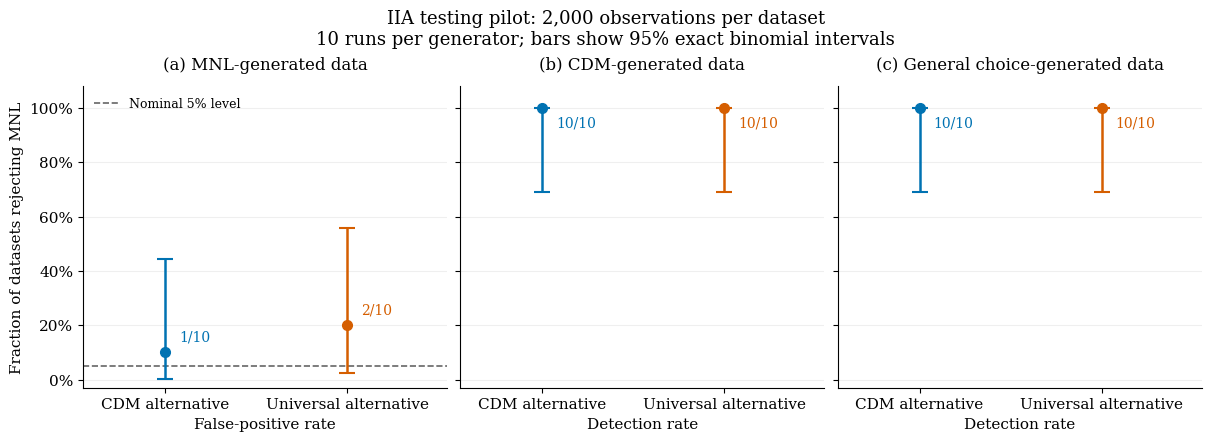

Figures saved to: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/cdm_paper_reproduction/02_synthetic_iia_tests/pilot_m2000_20261014T221636_471598Z


In [24]:
# Plot pilot rejection rates with exact confidence intervals and save the figure.

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

model_order = ["MNL", "CDM", "General choice"]
test_order = ["MNL vs CDM", "MNL vs Universal"]
test_labels = ["CDM alternative", "Universal alternative"]
test_colours = ["#0072B2", "#D55E00"]

pilot_figure_directory = FIGURE_DIRECTORY / pilot_run_id
pilot_figure_directory.mkdir(parents=True, exist_ok=True)

with plt.rc_context({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):
    figure, axes = plt.subplots(
        1,
        3,
        figsize=(12, 4.3),
        sharey=True,
        constrained_layout=True,
    )

    for panel_index, (axis, model_name) in enumerate(
        zip(axes, model_order)
    ):
        subset = (
            pilot_summary_with_ci.loc[
                pilot_summary_with_ci["Generating model"].eq(model_name)
            ]
            .set_index("Test")
            .loc[test_order]
        )

        for position, (test_name, colour) in enumerate(
            zip(test_order, test_colours)
        ):
            row = subset.loc[test_name]

            rate = float(
                row["Rejection rate among computed tests"]
            )
            lower = float(row["95% CI lower"])
            upper = float(row["95% CI upper"])

            axis.errorbar(
                position,
                rate,
                yerr=[
                    [max(0.0, rate - lower)],
                    [max(0.0, upper - rate)],
                ],
                fmt="o",
                color=colour,
                markersize=7,
                capsize=6,
                elinewidth=1.8,
                capthick=1.5,
                zorder=3,
            )

            axis.annotate(
                f"{int(row['Rejections'])}/{int(row['Computed tests'])}",
                xy=(position, rate),
                xytext=(10, -14 if rate > 0.9 else 8),
                textcoords="offset points",
                color=colour,
                fontsize=10,
            )

        if model_name == "MNL":
            axis.axhline(
                SIGNIFICANCE_LEVEL,
                color="0.4",
                linestyle="--",
                linewidth=1.2,
                label="Nominal 5% level",
            )
            axis.legend(
                loc="upper left",
                frameon=False,
                fontsize=9,
            )

        axis.set_title(
            f"({chr(97 + panel_index)}) {model_name}-generated data",
            pad=12,
        )
        axis.set_xticks([0, 1], test_labels)
        axis.set_xlim(-0.45, 1.55)
        axis.set_ylim(-0.03, 1.08)
        axis.set_yticks(np.linspace(0, 1, 6))
        axis.yaxis.set_major_formatter(PercentFormatter(1.0))
        axis.grid(axis="y", alpha=0.2)
        axis.set_axisbelow(True)
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

        axis.set_xlabel(
            "False-positive rate"
            if model_name == "MNL"
            else "Detection rate"
        )

    axes[0].set_ylabel("Fraction of datasets rejecting MNL")

    figure.suptitle(
        "IIA testing pilot: 2,000 observations per dataset\n"
        "10 runs per generator; bars show 95% exact binomial intervals",
        fontsize=13,
    )

    figure.savefig(
        pilot_figure_directory / "01_iia_pilot_rejection_rates.pdf",
        bbox_inches="tight",
    )

    figure.savefig(
        pilot_figure_directory / "01_iia_pilot_rejection_rates.png",
        bbox_inches="tight",
        dpi=300,
    )

    plt.show()

print("Figures saved to:", pilot_figure_directory)

## Rejection Rates as the Number of Observations Increases

Within each independent run, generate a pool of 2,000 observations
and fit fresh models to increasing prefixes of that pool.

Keep generating probabilities fixed across runs.
Use observed-menu design ranks to calculate identifiable model dimensions.

Retain failed fits and unavailable tests in the results.
This ten-run scaling pilot checks the workflow before a larger experiment.

In [25]:
# Configure the scaling pilot and verify dimensions on the full catalogue.

import importlib
import json
from datetime import datetime, timezone

import cdm_paper_reproduction.iia_scaling as iia_scaling

importlib.reload(iia_scaling)

SCALING_OBSERVATION_COUNTS = (
    100, 200, 400, 600, 800, 1_000, 1_500, 2_000
)
SCALING_RUNS = 10
SCALING_BASE_SEED = SEED + 200_000

full_dimensions = iia_scaling.get_observed_model_dimensions(
    catalogue_choice_sets=catalogue_choice_sets,
    catalogue_choice_mask=catalogue_choice_mask,
    menu_counts=np.ones(len(catalogue_choice_sets), dtype=int),
    number_of_items=NUMBER_OF_ITEMS,
)

if NUMBER_OF_ITEMS == 6:
    assert full_dimensions == {
        "MNL": 5,
        "CDM": 29,
        "Universal": 129,
    }

scaling_run_id = datetime.now(timezone.utc).strftime(
    "scaling_pilot_%Y%m%dT%H%M%S_%fZ"
)

scaling_directory = RESULT_DIRECTORY / scaling_run_id
scaling_directory.mkdir(parents=True, exist_ok=False)

scaling_settings = {
    "number_of_items": NUMBER_OF_ITEMS,
    "observation_counts": list(SCALING_OBSERVATION_COUNTS),
    "runs_per_setting": SCALING_RUNS,
    "base_seed": SCALING_BASE_SEED,
    "significance_level": SIGNIFICANCE_LEVEL,
    "generating_models": list(true_probability_tables),
    "sampling": "uniform menus; increasing prefixes within each run",
    "dimensions": "design ranks on observed menus",
    "maximum_epochs": 5_000,
    "reference_distribution": "asymptotic chi-square",
}

with (scaling_directory / "settings.json").open(
    "w", encoding="utf-8"
) as settings_file:
    json.dump(scaling_settings, settings_file, indent=2)

np.savez_compressed(
    scaling_directory / "generating_probability_tables.npz",
    catalogue_choice_sets=catalogue_choice_sets.cpu().numpy(),
    catalogue_choice_mask=catalogue_choice_mask.cpu().numpy(),
    **{
        name.lower().replace(" ", "_"): table.detach().cpu().numpy()
        for name, table in true_probability_tables.items()
    },
)

total_attempts = (
    SCALING_RUNS
    * len(SCALING_OBSERVATION_COUNTS)
    * len(true_probability_tables)
)

print("Full-catalogue dimensions:", full_dimensions)
print("Dataset fits to attempt:", total_attempts)
print("Results directory:", scaling_directory)

Full-catalogue dimensions: {'MNL': 5, 'CDM': 29, 'Universal': 129}
Dataset fits to attempt: 240
Results directory: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/experiments/cdm_paper_reproduction/02_synthetic_iia_tests/scaling_pilot_20261014T222227_304978Z


In [26]:
# Fit models to growing dataset prefixes and checkpoint every attempt.

scaling_rows = []
completed_attempts = 0

for run_number in range(1, SCALING_RUNS + 1):
    menu_seed = SCALING_BASE_SEED + 10 * run_number

    menu_generator = torch.Generator(device="cpu")
    menu_generator.manual_seed(menu_seed)

    full_menu_indices = torch.randint(
        low=0,
        high=len(catalogue_choice_sets),
        size=(max(SCALING_OBSERVATION_COUNTS),),
        generator=menu_generator,
    ).to(catalogue_choice_sets.device)

    for model_index, (model_name, probability_table) in enumerate(
        true_probability_tables.items(),
        start=1,
    ):
        outcome_seed = menu_seed + model_index

        full_data = sample_choices_from_probability_table(
            catalogue_choice_sets=catalogue_choice_sets,
            catalogue_choice_mask=catalogue_choice_mask,
            probability_table=probability_table,
            menu_indices=full_menu_indices,
            random_seed=outcome_seed,
        )

        model_slug = model_name.lower().replace(" ", "_")

        np.savez_compressed(
            scaling_directory
            / f"run_{run_number:03d}_{model_slug}_pool.npz",
            choice_sets=full_data.choice_sets.cpu().numpy(),
            choice_mask=full_data.choice_mask.cpu().numpy(),
            chosen_positions=full_data.chosen_positions.cpu().numpy(),
        )

        for number_of_observations in SCALING_OBSERVATION_COUNTS:
            completed_attempts += 1

            current_data = type(full_data)(
                choice_sets=full_data.choice_sets[
                    :number_of_observations
                ],
                choice_mask=full_data.choice_mask[
                    :number_of_observations
                ],
                chosen_positions=full_data.chosen_positions[
                    :number_of_observations
                ],
            )

            row = {
                "Run": run_number,
                "Generating model": model_name,
                "Observations": number_of_observations,
                "Menu seed": menu_seed,
                "Outcome seed": outcome_seed,
                "CDM p-value": np.nan,
                "Universal p-value": np.nan,
            }

            print(
                f"{completed_attempts}/{total_attempts} | "
                f"{model_name} | run={run_number} | "
                f"m={number_of_observations:,}"
            )

            try:
                result = iia_scaling.run_observed_menu_iia_tests(
                    data=current_data,
                    catalogue_choice_sets=catalogue_choice_sets,
                    catalogue_choice_mask=catalogue_choice_mask,
                    number_of_items=NUMBER_OF_ITEMS,
                    significance_level=SIGNIFICANCE_LEVEL,
                    maximum_epochs=5_000,
                    dtype=DTYPE,
                )

                row.update(result)

                both_computed = (
                    result["CDM test computed"]
                    and result["Universal test computed"]
                )

                row["Status"] = (
                    "completed" if both_computed else "partial"
                )
                row["Error"] = ""

            except (
                ValueError,
                RuntimeError,
                np.linalg.LinAlgError,
            ) as error:
                row["Status"] = "failed"
                row["Error"] = f"{type(error).__name__}: {error}"
                print("  Failed:", row["Error"])

            scaling_rows.append(row)

            pd.DataFrame(scaling_rows).to_csv(
                scaling_directory / "trial_results.csv",
                index=False,
            )

scaling_results = pd.DataFrame(scaling_rows)

print("\nScaling pilot finished.")
display(
    scaling_results.groupby(
        ["Generating model", "Status"]
    ).size().rename("Attempts").reset_index()
)

1/240 | MNL | run=1 | m=100
2/240 | MNL | run=1 | m=200
3/240 | MNL | run=1 | m=400
4/240 | MNL | run=1 | m=600
5/240 | MNL | run=1 | m=800
6/240 | MNL | run=1 | m=1,000
7/240 | MNL | run=1 | m=1,500
8/240 | MNL | run=1 | m=2,000
9/240 | CDM | run=1 | m=100
10/240 | CDM | run=1 | m=200
11/240 | CDM | run=1 | m=400
12/240 | CDM | run=1 | m=600
13/240 | CDM | run=1 | m=800
14/240 | CDM | run=1 | m=1,000
15/240 | CDM | run=1 | m=1,500
16/240 | CDM | run=1 | m=2,000
17/240 | General choice | run=1 | m=100
18/240 | General choice | run=1 | m=200
19/240 | General choice | run=1 | m=400
20/240 | General choice | run=1 | m=600
21/240 | General choice | run=1 | m=800
22/240 | General choice | run=1 | m=1,000
23/240 | General choice | run=1 | m=1,500
24/240 | General choice | run=1 | m=2,000
25/240 | MNL | run=2 | m=100
26/240 | MNL | run=2 | m=200
27/240 | MNL | run=2 | m=400
28/240 | MNL | run=2 | m=600
29/240 | MNL | run=2 | m=800
30/240 | MNL | run=2 | m=1,000
31/240 | MNL | run=2 | m=1,500


,Generating model,Status,Attempts
0,CDM,completed,32
1,CDM,partial,48
2,General choice,completed,80
3,MNL,completed,80


In [27]:
# Summarize scaling results without counting unavailable tests as non-rejections.

from scipy.stats import binomtest

scaling_summary_rows = []

for (model_name, observation_count), group in scaling_results.groupby(
    ["Generating model", "Observations"],
    sort=False,
):
    for alternative in ["CDM", "Universal"]:
        p_values = pd.to_numeric(
            group[f"{alternative} p-value"],
            errors="coerce",
        )

        computed = p_values.notna()
        attempted_count = len(group)
        computed_count = int(computed.sum())
        missing_count = attempted_count - computed_count

        rejection_count = int(
            (p_values[computed] < SIGNIFICANCE_LEVEL).sum()
        )

        rate = (
            rejection_count / computed_count
            if computed_count
            else np.nan
        )

        if computed_count:
            interval = binomtest(
                rejection_count,
                computed_count,
            ).proportion_ci(
                confidence_level=0.95,
                method="exact",
            )
            lower, upper = interval.low, interval.high
        else:
            lower, upper = np.nan, np.nan

        scaling_summary_rows.append({
            "Generating model": model_name,
            "Observations": observation_count,
            "Test": f"MNL vs {alternative}",
            "Attempted datasets": attempted_count,
            "Computed tests": computed_count,
            "Missing tests": missing_count,
            "Rejections": rejection_count,
            "Rejection rate among computed tests": rate,
            "95% CI lower": lower,
            "95% CI upper": upper,
            "All-attempt rejection fraction lower bound": (
                rejection_count / attempted_count
            ),
            "All-attempt rejection fraction upper bound": (
                (rejection_count + missing_count) / attempted_count
            ),
        })

scaling_summary = pd.DataFrame(scaling_summary_rows)

scaling_summary.to_csv(
    scaling_directory / "rejection_summary.csv",
    index=False,
)

display(
    scaling_summary.style.format({
        "Rejection rate among computed tests": "{:.1%}",
        "95% CI lower": "{:.1%}",
        "95% CI upper": "{:.1%}",
        "All-attempt rejection fraction lower bound": "{:.1%}",
        "All-attempt rejection fraction upper bound": "{:.1%}",
    })
)

problem_rows = scaling_results.loc[
    scaling_results["Status"].ne("completed")
]

problem_rows.to_csv(
    scaling_directory / "attempts_requiring_review.csv",
    index=False,
)

print("Attempts requiring review:", len(problem_rows))

,Generating model,Observations,Test,Attempted datasets,Computed tests,Missing tests,Rejections,Rejection rate among computed tests,95% CI lower,95% CI upper,All-attempt rejection fraction lower bound,All-attempt rejection fraction upper bound
0,MNL,100,MNL vs CDM,10,10,0,2,20.0%,2.5%,55.6%,20.0%,20.0%
1,MNL,100,MNL vs Universal,10,10,0,0,0.0%,0.0%,30.8%,0.0%,0.0%
2,MNL,200,MNL vs CDM,10,10,0,2,20.0%,2.5%,55.6%,20.0%,20.0%
3,MNL,200,MNL vs Universal,10,10,0,1,10.0%,0.3%,44.5%,10.0%,10.0%
4,MNL,400,MNL vs CDM,10,10,0,1,10.0%,0.3%,44.5%,10.0%,10.0%
5,MNL,400,MNL vs Universal,10,10,0,2,20.0%,2.5%,55.6%,20.0%,20.0%
6,MNL,600,MNL vs CDM,10,10,0,2,20.0%,2.5%,55.6%,20.0%,20.0%
7,MNL,600,MNL vs Universal,10,10,0,2,20.0%,2.5%,55.6%,20.0%,20.0%
8,MNL,800,MNL vs CDM,10,10,0,2,20.0%,2.5%,55.6%,20.0%,20.0%
9,MNL,800,MNL vs Universal,10,10,0,3,30.0%,6.7%,65.2%,30.0%,30.0%


Attempts requiring review: 48


In [28]:
# Inspect test availability across generating models and observation counts.

test_availability = scaling_summary[
    [
        "Generating model",
        "Observations",
        "Test",
        "Attempted datasets",
        "Computed tests",
        "Missing tests",
        "Rejections",
    ]
].sort_values(
    ["Generating model", "Observations", "Test"]
)

with pd.option_context("display.max_rows", None):
    display(test_availability)

test_availability.to_csv(
    scaling_directory / "test_availability.csv",
    index=False,
)

,Generating model,Observations,Test,Attempted datasets,Computed tests,Missing tests,Rejections
16,CDM,100,MNL vs CDM,10,0,10,0
17,CDM,100,MNL vs Universal,10,10,0,9
18,CDM,200,MNL vs CDM,10,1,9,1
19,CDM,200,MNL vs Universal,10,10,0,10
20,CDM,400,MNL vs CDM,10,3,7,3
21,CDM,400,MNL vs Universal,10,10,0,10
22,CDM,600,MNL vs CDM,10,3,7,3
23,CDM,600,MNL vs Universal,10,10,0,10
24,CDM,800,MNL vs CDM,10,4,6,4
25,CDM,800,MNL vs Universal,10,10,0,10


In [29]:
# Inspect and summarize the recorded reasons for incomplete test results.

review_columns = [
    "Generating model",
    "Observations",
    "Run",
    "Status",
    "CDM converged",
    "CDM epochs",
    "CDM stopping reason",
    "CDM fit error",
    "CDM test issue",
    "Universal test issue",
    "Error",
]

review_rows = (
    scaling_results.loc[
        scaling_results["Status"].ne("completed")
    ]
    .reindex(columns=review_columns)
    .sort_values(["Generating model", "Observations", "Run"])
)

issue_records = []

for _, row in review_rows.iterrows():
    for field in [
        "CDM test issue",
        "Universal test issue",
        "CDM fit error",
        "Error",
    ]:
        message = row[field]

        if pd.notna(message) and str(message).strip():
            issue_records.append(
                {
                    "Generating model": row["Generating model"],
                    "Observations": row["Observations"],
                    "Diagnostic": field,
                    "Reason": str(message),
                }
            )

if issue_records:
    issue_summary = (
        pd.DataFrame(issue_records)
        .groupby(
            ["Generating model", "Observations", "Diagnostic", "Reason"],
            dropna=False,
        )
        .size()
        .reset_index(name="Occurrences")
    )

    with pd.option_context(
        "display.max_rows", None,
        "display.max_colwidth", None,
    ):
        display(issue_summary)
else:
    print("No diagnostic messages were recorded.")

with pd.option_context("display.max_colwidth", None):
    display(review_rows.head(12))

review_rows.to_csv(
    scaling_directory / "incomplete_test_diagnostics.csv",
    index=False,
)

print(f"Attempts requiring review: {len(review_rows)}")

,Generating model,Observations,Diagnostic,Reason,Occurrences
0,CDM,100,CDM test issue,CDM optimizer did not converge,10
1,CDM,200,CDM test issue,CDM optimizer did not converge,9
2,CDM,400,CDM test issue,CDM optimizer did not converge,7
3,CDM,600,CDM test issue,CDM optimizer did not converge,7
4,CDM,800,CDM test issue,CDM optimizer did not converge,6
5,CDM,1000,CDM test issue,CDM optimizer did not converge,6
6,CDM,1500,CDM test issue,CDM optimizer did not converge,2
7,CDM,2000,CDM test issue,CDM optimizer did not converge,1


,Generating model,Observations,Run,Status,CDM converged,CDM epochs,CDM stopping reason,CDM fit error,CDM test issue,Universal test issue,Error
8,CDM,100,1,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,
32,CDM,100,2,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,
56,CDM,100,3,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,
80,CDM,100,4,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,
104,CDM,100,5,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,
128,CDM,100,6,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,
152,CDM,100,7,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,
176,CDM,100,8,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,
200,CDM,100,9,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,
224,CDM,100,10,partial,False,5000,maximum epochs reached,,CDM optimizer did not converge,,


Attempts requiring review: 48


In [30]:
# Compare incomplete CDM likelihood-ratio values with the nominal test threshold.

from scipy.stats import chi2

incomplete_cdm_checks = scaling_results.loc[
    scaling_results["Generating model"].eq("CDM")
    & scaling_results["Status"].ne("completed"),
    [
        "Run",
        "Observations",
        "MNL mean NLL",
        "CDM mean NLL",
        "Universal mean NLL",
        "CDM degrees of freedom",
        "CDM epochs",
        "CDM stopping reason",
    ],
].copy()

incomplete_cdm_checks["Current LR statistic"] = (
    2
    * incomplete_cdm_checks["Observations"]
    * (
        incomplete_cdm_checks["MNL mean NLL"]
        - incomplete_cdm_checks["CDM mean NLL"]
    )
)

incomplete_cdm_checks["Nominal critical value"] = chi2.isf(
    SIGNIFICANCE_LEVEL,
    incomplete_cdm_checks["CDM degrees of freedom"],
)

incomplete_cdm_checks["Likelihood ordering valid"] = (
    np.isfinite(incomplete_cdm_checks["Current LR statistic"])
    & (
        incomplete_cdm_checks["CDM mean NLL"]
        <= incomplete_cdm_checks["MNL mean NLL"] + 1e-8
    )
    & (
        incomplete_cdm_checks["CDM mean NLL"]
        >= incomplete_cdm_checks["Universal mean NLL"] - 1e-8
    )
)

incomplete_cdm_checks["Threshold already exceeded"] = (
    incomplete_cdm_checks["Likelihood ordering valid"]
    & (
        incomplete_cdm_checks["Current LR statistic"]
        > incomplete_cdm_checks["Nominal critical value"]
    )
)

display(incomplete_cdm_checks.head(12).round(4))

,Run,Observations,MNL mean NLL,CDM mean NLL,Universal mean NLL,CDM degrees of freedom,CDM epochs,CDM stopping reason,Current LR statistic,Nominal critical value,Likelihood ordering valid,Threshold already exceeded
8,1,100,0.8420,0.1363,0.1175,24,5000,maximum epochs reached,141.1357,36.415,True,True
9,1,200,0.8183,0.2790,0.2370,24,5000,maximum epochs reached,215.7313,36.415,True,True
10,1,400,0.8101,0.3373,0.2884,24,5000,maximum epochs reached,378.2232,36.415,True,True
11,1,600,0.8445,0.3627,0.3240,24,5000,maximum epochs reached,578.1290,36.415,True,True
12,1,800,0.8382,0.3716,0.3474,24,5000,maximum epochs reached,746.6708,36.415,True,True
13,1,1000,0.8436,0.3619,0.3406,24,5000,maximum epochs reached,963.3716,36.415,True,True
32,2,100,0.8202,0.1964,0.1596,24,5000,maximum epochs reached,124.7639,36.415,True,True
33,2,200,0.8529,0.2318,0.1981,24,5000,maximum epochs reached,248.4049,36.415,True,True
34,2,400,0.9040,0.3418,0.2754,24,5000,maximum epochs reached,449.7530,36.415,True,True
56,3,100,0.8248,0.1522,0.1473,24,5000,maximum epochs reached,134.5229,36.415,True,True


In [31]:
# Summarize threshold crossings without changing the original convergence results.

incomplete_threshold_summary = (
    incomplete_cdm_checks.groupby("Observations", as_index=False)
    .agg(
        Incomplete_fits=("Run", "size"),
        Valid_likelihood_ordering=("Likelihood ordering valid", "sum"),
        Threshold_already_exceeded=("Threshold already exceeded", "sum"),
    )
)

incomplete_threshold_summary["Threshold unresolved"] = (
    incomplete_threshold_summary["Incomplete_fits"]
    - incomplete_threshold_summary["Threshold_already_exceeded"]
)

display(incomplete_threshold_summary)

incomplete_cdm_checks.to_csv(
    scaling_directory / "incomplete_cdm_threshold_checks.csv",
    index=False,
)

incomplete_threshold_summary.to_csv(
    scaling_directory / "incomplete_cdm_threshold_summary.csv",
    index=False,
)

,Observations,Incomplete_fits,Valid_likelihood_ordering,Threshold_already_exceeded,Threshold unresolved
0,100,10,10,10,0
1,200,9,9,9,0
2,400,7,7,7,0
3,600,7,7,7,0
4,800,6,6,6,0
5,1000,6,6,6,0
6,1500,2,2,2,0
7,2000,1,1,1,0


In [32]:
# Refit one saved incomplete CDM dataset and retain its optimization history.

from bradley_terry.choix_estimation import (
    estimate_top1_parameters_with_choix,
)
from context_dependent_model.model import center_cdm_parameters
from context_dependent_model.simulation import CDMChoiceData
from cdm_paper_reproduction.estimation import (
    optimize_full_cdm_with_adam,
)

diagnostic_row = (
    scaling_results.loc[
        scaling_results["Generating model"].eq("CDM")
        & scaling_results["Status"].ne("completed")
    ]
    .sort_values(["Observations", "Run"])
    .iloc[0]
)

diagnostic_run = int(diagnostic_row["Run"])
diagnostic_observations = int(diagnostic_row["Observations"])

pool_path = (
    scaling_directory
    / f"run_{diagnostic_run:03d}_cdm_pool.npz"
)

with np.load(pool_path) as saved_pool:
    diagnostic_data = CDMChoiceData(
        choice_sets=torch.as_tensor(
            saved_pool["choice_sets"][:diagnostic_observations],
            dtype=torch.long,
            device=DEVICE,
        ),
        choice_mask=torch.as_tensor(
            saved_pool["choice_mask"][:diagnostic_observations],
            dtype=torch.bool,
            device=DEVICE,
        ),
        chosen_positions=torch.as_tensor(
            saved_pool["chosen_positions"][:diagnostic_observations],
            dtype=torch.long,
            device=DEVICE,
        ),
    )

diagnostic_choices = [
    (
        int(items[int(position)].item()),
        tuple(int(item) for item in items[mask].tolist()),
    )
    for items, mask, position in zip(
        diagnostic_data.choice_sets,
        diagnostic_data.choice_mask,
        diagnostic_data.chosen_positions,
    )
]

diagnostic_mnl_parameters = estimate_top1_parameters_with_choix(
    number_of_items=NUMBER_OF_ITEMS,
    observations=diagnostic_choices,
    alpha=0.0,
    maximum_iterations=10_000,
    tolerance=1e-10,
)

diagnostic_theta = torch.as_tensor(
    diagnostic_mnl_parameters,
    dtype=DTYPE,
    device=DEVICE,
)

diagnostic_initial_interactions = center_cdm_parameters(
    -diagnostic_theta.unsqueeze(0)
    .expand(NUMBER_OF_ITEMS, -1)
    .clone()
)

diagnostic_fit = optimize_full_cdm_with_adam(
    number_of_items=NUMBER_OF_ITEMS,
    training_data=diagnostic_data,
    initial_interactions=diagnostic_initial_interactions,
    learning_rate=0.05,
    gradient_tolerance=1e-5,
    nll_tolerance=1e-9,
    patience=50,
    maximum_epochs=5_000,
    dtype=DTYPE,
)

print(
    f"Dataset: CDM | run={diagnostic_run} "
    f"| observations={diagnostic_observations}"
)
print("Converged:", diagnostic_fit.converged)
print("Stopping reason:", diagnostic_fit.stopping_reason)
print("Epochs:", diagnostic_fit.epochs_completed)

Dataset: CDM | run=1 | observations=100
Converged: False
Stopping reason: maximum epochs reached
Epochs: 5000


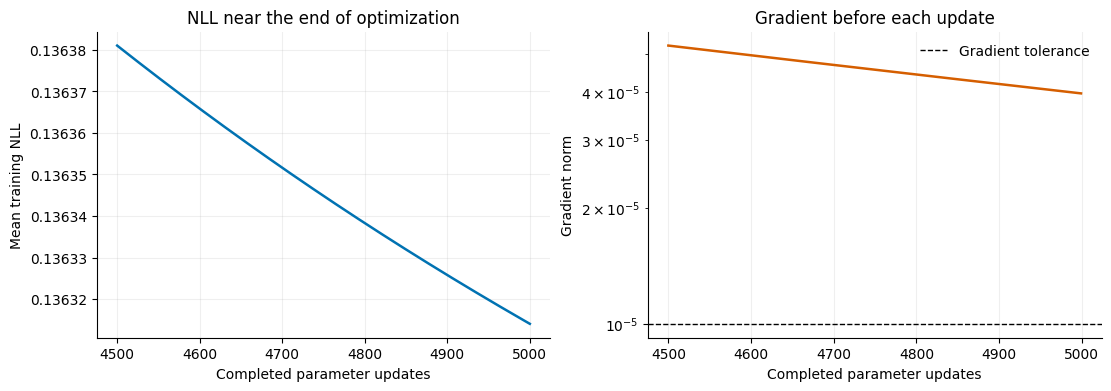

Final NLL: 0.1363140506
Last recorded pre-update gradient norm: 3.961275e-05
Largest absolute NLL change over the last 50 updates: 1.173265e-07
Final interaction-matrix norm: 49.091619


In [33]:
# Inspect the final optimization trajectory with correctly aligned history indices.

diagnostic_nll = np.asarray(
    diagnostic_fit.nll_history,
    dtype=float,
)

diagnostic_gradients = np.asarray(
    diagnostic_fit.gradient_norm_history,
    dtype=float,
)

diagnostic_tail_start = max(0, len(diagnostic_nll) - 501)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(11, 3.8),
    constrained_layout=True,
)

axes[0].plot(
    np.arange(len(diagnostic_nll))[diagnostic_tail_start:],
    diagnostic_nll[diagnostic_tail_start:],
    color="#0072B2",
    linewidth=1.8,
)

axes[0].set(
    title="NLL near the end of optimization",
    xlabel="Completed parameter updates",
    ylabel="Mean training NLL",
)

axes[0].ticklabel_format(
    axis="y",
    style="plain",
    useOffset=False,
)

axes[1].semilogy(
    np.arange(len(diagnostic_gradients))[diagnostic_tail_start:],
    np.maximum(
        diagnostic_gradients[diagnostic_tail_start:],
        np.finfo(float).tiny,
    ),
    color="#D55E00",
    linewidth=1.8,
)

axes[1].axhline(
    1e-5,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Gradient tolerance",
)

axes[1].set(
    title="Gradient before each update",
    xlabel="Completed parameter updates",
    ylabel="Gradient norm",
)

axes[1].legend(frameon=False)

for axis in axes:
    axis.grid(alpha=0.2)
    axis.spines[["top", "right"]].set_visible(False)

plt.show()

last_changes = np.abs(np.diff(diagnostic_nll))[-50:]

print(f"Final NLL: {diagnostic_nll[-1]:.10f}")
print(
    "Last recorded pre-update gradient norm: "
    f"{diagnostic_gradients[-1]:.6e}"
)
print(
    "Largest absolute NLL change over the last 50 updates: "
    f"{last_changes.max():.6e}"
)
print(
    "Final interaction-matrix norm: "
    f"{diagnostic_fit.interaction_matrix.norm().item():.6f}"
)

In [35]:
# Check the diagnostic dataset for a separating full-CDM direction.

import importlib
import cdm_paper_reproduction.iia_separation as iia_separation

importlib.reload(iia_separation)

separation_diagnostic = iia_separation.diagnose_cdm_separation(
    data=diagnostic_data,
    number_of_items=NUMBER_OF_ITEMS,
)

separation_summary = pd.DataFrame(
    [
        {"Diagnostic": name, "Value": value}
        for name, value in separation_diagnostic.items()
        if name != "Direction matrix"
    ]
)

display(separation_summary)

separation_summary.to_csv(
    scaling_directory
    / (
        f"separation_run_{diagnostic_run:03d}"
        f"_m{diagnostic_observations}.csv"
    ),
    index=False,
)

,Diagnostic,Value
0,Separation detected,True
1,Unique contrast constraints,114
2,Minimum directional margin,0.0
3,Maximum directional margin,6.0
4,Mean directional margin,1.842105
5,Strictly improved contrasts,75
6,Solver message,Optimization terminated successfully. (HiGHS S...


In [36]:
# Diagnose separation in every saved CDM-generated scaling dataset.

cdm_trial_rows = (
    scaling_results.loc[
        scaling_results["Generating model"].eq("CDM"),
        [
            "Run",
            "Observations",
            "Status",
            "CDM converged",
            "CDM stopping reason",
        ],
    ]
    .sort_values(["Run", "Observations"])
)

separation_rows = []

for run_number, run_rows in cdm_trial_rows.groupby("Run"):
    pool_path = (
        scaling_directory
        / f"run_{int(run_number):03d}_cdm_pool.npz"
    )

    with np.load(pool_path) as saved_pool:
        pool_choice_sets = saved_pool["choice_sets"].copy()
        pool_choice_mask = saved_pool["choice_mask"].copy()
        pool_chosen_positions = saved_pool["chosen_positions"].copy()

    for _, trial in run_rows.iterrows():
        observation_count = int(trial["Observations"])

        current_data = CDMChoiceData(
            choice_sets=torch.as_tensor(
                pool_choice_sets[:observation_count],
                dtype=torch.long,
            ),
            choice_mask=torch.as_tensor(
                pool_choice_mask[:observation_count],
                dtype=torch.bool,
            ),
            chosen_positions=torch.as_tensor(
                pool_chosen_positions[:observation_count],
                dtype=torch.long,
            ),
        )

        diagnostic = iia_separation.diagnose_cdm_separation(
            data=current_data,
            number_of_items=NUMBER_OF_ITEMS,
        )

        separation_rows.append(
            {
                "Run": int(run_number),
                "Observations": observation_count,
                "CDM converged": bool(trial["CDM converged"]),
                "CDM stopping reason": trial["CDM stopping reason"],
                **{
                    name: value
                    for name, value in diagnostic.items()
                    if name != "Direction matrix"
                },
            }
        )

    pd.DataFrame(separation_rows).to_csv(
        scaling_directory / "cdm_separation_diagnostics.csv",
        index=False,
    )

    print(f"Separation checks completed for run {int(run_number)}.")

cdm_separation_results = pd.DataFrame(separation_rows)

Separation checks completed for run 1.
Separation checks completed for run 2.
Separation checks completed for run 3.
Separation checks completed for run 4.
Separation checks completed for run 5.
Separation checks completed for run 6.
Separation checks completed for run 7.
Separation checks completed for run 8.
Separation checks completed for run 9.
Separation checks completed for run 10.


In [37]:
# Compare numerical convergence with detected separation at each sample size.

cdm_separation_results["Converged with separation"] = (
    cdm_separation_results["CDM converged"]
    & cdm_separation_results["Separation detected"]
)

cdm_separation_results["Not converged with separation"] = (
    ~cdm_separation_results["CDM converged"]
    & cdm_separation_results["Separation detected"]
)

cdm_separation_results["Not converged without detected separation"] = (
    ~cdm_separation_results["CDM converged"]
    & ~cdm_separation_results["Separation detected"]
)

cdm_separation_summary = (
    cdm_separation_results.groupby("Observations", as_index=False)
    .agg(
        Datasets=("Run", "size"),
        Separation_detected=("Separation detected", "sum"),
        Optimizer_converged=("CDM converged", "sum"),
        Converged_with_separation=("Converged with separation", "sum"),
        Not_converged_with_separation=(
            "Not converged with separation",
            "sum",
        ),
        Not_converged_without_detected_separation=(
            "Not converged without detected separation",
            "sum",
        ),
    )
)

display(cdm_separation_summary)

cdm_separation_results.to_csv(
    scaling_directory / "cdm_separation_diagnostics.csv",
    index=False,
)

cdm_separation_summary.to_csv(
    scaling_directory / "cdm_separation_summary.csv",
    index=False,
)

,Observations,Datasets,Separation_detected,Optimizer_converged,Converged_with_separation,Not_converged_with_separation,Not_converged_without_detected_separation
0,100,10,10,0,0,10,0
1,200,10,10,1,1,9,0
2,400,10,10,3,3,7,0
3,600,10,8,3,1,7,0
4,800,10,7,4,1,6,0
5,1000,10,7,4,1,6,0
6,1500,10,5,8,3,2,0
7,2000,10,3,9,2,1,0


### Separation and numerical convergence

Across 80 CDM-generated datasets, the linear-programming diagnostic
detected separation in 60 datasets. All 48 fits that reached the
iteration limit were among these separated datasets. A further 12
separated datasets satisfied the optimizer's numerical stopping
criteria.

Thus, numerical convergence does not establish the existence of a
finite unconstrained CDM maximum-likelihood estimate. Detected
separation decreased from 10/10 datasets at 100 observations to
3/10 at 2,000 observations.

All 48 incomplete fits already exceeded the nominal likelihood-ratio
rejection threshold at their current parameter values. These threshold
crossings are retained separately from converged-fit results and do
not establish finite-sample calibration of the chi-square test.